# Black-Scholes Greeks: Three Methods, Cross-Validated

This notebook computes the **Greeks** — the sensitivities of an option's price to its inputs — three independent ways and checks that they agree:

1. **Analytical** — the closed-form calculus formulas
2. **Finite difference** — bump an input, reprice, divide by the bump
3. **Autograd** — let PyTorch differentiate the price automatically

## Why three methods?
Each is a different route to the same numbers, so agreement between them is strong evidence all three are correct:
- The **analytical** formulas are exact but easy to get wrong by hand → finite-difference checks them.
- **Finite difference** is universal (works on any pricer, even one with no formula) but has numerical error → the bump size matters, and we'll see the bias-variance tradeoff explicitly.
- **Autograd** is exact (no truncation error) and needs no hand-derived formulas → it's how modern risk engines get Greeks for complex models.

## The Greeks we compute
- **Delta** ($\partial V/\partial S$) — sensitivity to the underlying price
- **Gamma** ($\partial^2 V/\partial S^2$) — how delta changes (second-order)
- **Vega** ($\partial V/\partial \sigma$) — sensitivity to volatility
- **Theta** ($\partial V/\partial t$) — time decay
- **Rho** ($\partial V/\partial r$) — sensitivity to interest rate

In [1]:
import numpy as np
from scipy.stats import norm
import torch
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)


---
# 1. The Black-Scholes price

Everything starts from the European call price:

$$C = S\, N(d_1) - K e^{-rT} N(d_2)$$

$$d_1 = \frac{\ln(S/K) + (r + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

where $N(\cdot)$ is the standard normal CDF. The Greeks are just the derivatives of this expression with respect to each input — so before computing sensitivities, we need a clean price function.

In [2]:
def bs_call_price(S, K, T, r, sigma):
    """Black-Scholes European call price (NumPy/analytical)."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


S, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20
price = bs_call_price(S, K, T, r, sigma)
print(f"Reference call: S={S}, K={K}, T={T}, r={r}, sigma={sigma}")
print(f"Price = {price:.6f}")


Reference call: S=100.0, K=100.0, T=1.0, r=0.05, sigma=0.2
Price = 10.450584


---
# 2. Method 1 — Analytical Greeks (closed form)

Differentiating the Black-Scholes formula by hand gives exact expressions. These are the formulas every options desk uses:

$$\Delta = N(d_1) \qquad \Gamma = \frac{N'(d_1)}{S\sigma\sqrt{T}} \qquad \nu = S\, N'(d_1)\sqrt{T}$$

$$\Theta = -\frac{S\,N'(d_1)\sigma}{2\sqrt{T}} - rK e^{-rT} N(d_2) \qquad \rho = K T e^{-rT} N(d_2)$$

where $N'(\cdot)$ is the normal **PDF**.

In [3]:
def bs_greeks_analytical(S, K, T, r, sigma):
    """All five Greeks in closed form."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf_d1 = norm.pdf(d1)

    delta = norm.cdf(d1)
    gamma = pdf_d1 / (S * sigma * np.sqrt(T))
    vega = S * pdf_d1 * np.sqrt(T)
    theta = -S * pdf_d1 * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(
        d2
    )
    rho = K * T * np.exp(-r * T) * norm.cdf(d2)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}


analytical = bs_greeks_analytical(S, K, T, r, sigma)
for name, val in analytical.items():
    print(f"  {name:>6}: {val:+.6f}")


   delta: +0.636831
   gamma: +0.018762
    vega: +37.524035
   theta: -6.414028
     rho: +53.232482


---
# 3. Method 2 — Finite-difference Greeks

The definition of a derivative: bump the input by a small $\varepsilon$, see how the price changes.

**Central difference** (more accurate than one-sided):
$$\frac{\partial V}{\partial x} \approx \frac{V(x+\varepsilon) - V(x-\varepsilon)}{2\varepsilon}$$

**Second derivative** (for gamma):
$$\frac{\partial^2 V}{\partial S^2} \approx \frac{V(S+\varepsilon) - 2V(S) + V(S-\varepsilon)}{\varepsilon^2}$$

This needs **no formulas** — it works on any pricer, which is why it's the universal sanity check. The catch is choosing $\varepsilon$ (next section).

Note: theta is $-\partial V/\partial T$ — the price's calendar-time decay is the *negative* of its sensitivity to time-to-expiry.

In [4]:
def bs_greeks_finite_diff(S, K, T, r, sigma, eps=1e-4):
    """All five Greeks by central finite differences."""
    f = bs_call_price
    delta = (f(S + eps, K, T, r, sigma) - f(S - eps, K, T, r, sigma)) / (2 * eps)
    gamma = (
        f(S + eps, K, T, r, sigma)
        - 2 * f(S, K, T, r, sigma)
        + f(S - eps, K, T, r, sigma)
    ) / (eps**2)
    vega = (f(S, K, T, r, sigma + eps) - f(S, K, T, r, sigma - eps)) / (2 * eps)

    theta = -(f(S, K, T + eps, r, sigma) - f(S, K, T - eps, r, sigma)) / (2 * eps)
    rho = (f(S, K, T, r + eps, sigma) - f(S, K, T, r - eps, sigma)) / (2 * eps)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}


finite_diff = bs_greeks_finite_diff(S, K, T, r, sigma)
for name, val in finite_diff.items():
    print(f"  {name:>6}: {val:+.6f}")


   delta: +0.636831
   gamma: +0.018762
    vega: +37.524034
   theta: -6.414028
     rho: +53.232481


---
# 4. Method 3 — Autograd Greeks (PyTorch automatic differentiation)

Re-implement the price using PyTorch, mark the inputs as requiring gradients, and call `.backward()`. PyTorch computes the **exact** derivatives by applying the chain rule through every operation — no formulas, no truncation error.

- **First-order Greeks** (delta, vega, theta, rho) come from one `.backward()` call — they're the gradients of the price with respect to each input.
- **Gamma** is a second derivative, so we differentiate delta again (`torch.autograd.grad` with `create_graph=True` to keep the graph alive for the second pass).

This is exactly how production risk engines compute sensitivities for models with no closed form — and it's the cheap way to add Greeks to the neural-network pricer.

In [5]:
def bs_greeks_autograd(S, K, T, r, sigma):
    """All five Greeks via PyTorch automatic differentiation."""
    S_t = torch.tensor(S, dtype=torch.float64, requires_grad=True)
    T_t = torch.tensor(T, dtype=torch.float64, requires_grad=True)
    r_t = torch.tensor(r, dtype=torch.float64, requires_grad=True)
    sig_t = torch.tensor(sigma, dtype=torch.float64, requires_grad=True)
    K_t = torch.tensor(K, dtype=torch.float64)

    normal = torch.distributions.Normal(0.0, 1.0)
    d1 = (torch.log(S_t / K_t) + (r_t + 0.5 * sig_t**2) * T_t) / (
        sig_t * torch.sqrt(T_t)
    )
    d2 = d1 - sig_t * torch.sqrt(T_t)
    price = S_t * normal.cdf(d1) - K_t * torch.exp(-r_t * T_t) * normal.cdf(d2)

    grads = torch.autograd.grad(price, [S_t, sig_t, T_t, r_t], create_graph=True)
    delta, vega, dV_dT, rho = grads
    theta = -dV_dT

    gamma = torch.autograd.grad(delta, S_t, retain_graph=True)[0]

    return {
        "delta": delta.item(),
        "gamma": gamma.item(),
        "vega": vega.item(),
        "theta": theta.item(),
        "rho": rho.item(),
    }


autograd = bs_greeks_autograd(S, K, T, r, sigma)
for name, val in autograd.items():
    print(f"  {name:>6}: {val:+.6f}")


   delta: +0.636831
   gamma: +0.018762
    vega: +37.524035
   theta: -6.414028
     rho: +53.232482


---
# 5. Cross-validation: do all three agree?

This is the payoff. If the analytical formulas, the finite differences, and the autograd results all match to high precision, we have strong evidence every method is correct. The analytical and autograd should agree to ~machine precision; finite difference will be very close but slightly off due to its inherent numerical error.

In [6]:
import pandas as pd

table = pd.DataFrame(
    {
        "Analytical": analytical,
        "FiniteDiff": finite_diff,
        "Autograd": autograd,
    }
)
table["max_abs_diff"] = table.max(axis=1) - table.min(axis=1)
print("Greeks computed three ways:")
print(table.round(6).to_string())
print()
print(f"Largest disagreement across all Greeks: {table['max_abs_diff'].max():.2e}")
print("(Analytical vs Autograd should match to ~machine precision;")
print(" FiniteDiff is slightly off due to truncation/rounding error.)")


Greeks computed three ways:
       Analytical  FiniteDiff   Autograd  max_abs_diff
delta    0.636831    0.636831   0.636831      0.000000
gamma    0.018762    0.018762   0.018762      0.000000
vega    37.524035   37.524034  37.524035      0.000000
theta   -6.414028   -6.414028  -6.414028      0.000000
rho     53.232482   53.232481  53.232482      0.000001

Largest disagreement across all Greeks: 7.71e-07
(Analytical vs Autograd should match to ~machine precision;
 FiniteDiff is slightly off due to truncation/rounding error.)


---
# 6. The finite-difference bump size: a bias-variance tradeoff

Finite difference has one free parameter — the bump size $\varepsilon$ — and choosing it is a genuine tradeoff:

- **$\varepsilon$ too large** → *truncation bias*. The difference quotient is only an approximation to the derivative; a big bump means the approximation is poor (you're measuring a secant over a wide interval, not the tangent).
- **$\varepsilon$ too small** → *rounding noise*. You subtract two nearly-equal floating-point numbers and divide by a tiny number, amplifying floating-point error catastrophically.

The error is U-shaped in $\varepsilon$: there's a sweet spot in the middle. Let's measure it by comparing finite-difference delta against the exact analytical delta across many bump sizes.

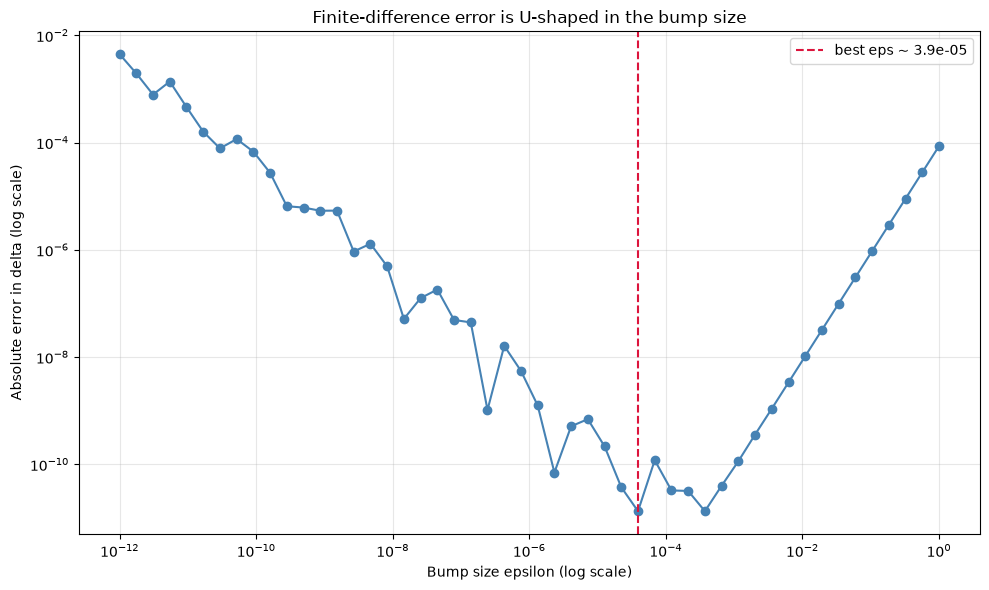

Best bump size found: 3.91e-05
Error there: 1.33e-11
Left branch = rounding noise (eps too small); right branch = truncation bias (eps too large).


In [7]:
exact_delta = analytical["delta"]
eps_values = np.logspace(-12, 0, 50)
fd_errors = []
for eps in eps_values:
    fd = (
        bs_call_price(S + eps, K, T, r, sigma) - bs_call_price(S - eps, K, T, r, sigma)
    ) / (2 * eps)
    fd_errors.append(abs(fd - exact_delta))

fd_errors = np.array(fd_errors)
best_eps = eps_values[np.argmin(fd_errors)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(eps_values, fd_errors, "o-", color="steelblue")
ax.axvline(best_eps, color="crimson", ls="--", label=f"best eps ~ {best_eps:.1e}")
ax.set_xlabel("Bump size epsilon (log scale)")
ax.set_ylabel("Absolute error in delta (log scale)")
ax.set_title("Finite-difference error is U-shaped in the bump size")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

print(f"Best bump size found: {best_eps:.2e}")
print(f"Error there: {fd_errors.min():.2e}")
print(
    "Left branch = rounding noise (eps too small);"
    " right branch = truncation bias (eps too large)."
)
